In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\chauh\Downloads\linear_regression_ad_spend_sales.csv")
df

,Advertising_Spend_Thousand_INR,Sales_Thousand_INR
0,13,34.48
1,79,242.77
2,67,158.54
3,47,133.50
4,46,140.86
...,...,...
115,59,146.89
116,8,13.24
117,18,68.25
118,28,122.38


In [3]:
df.shape

(120, 2)

In [4]:
print(df.isnull())

     Advertising_Spend_Thousand_INR  Sales_Thousand_INR
0                             False               False
1                             False               False
2                             False               False
3                             False               False
4                             False               False
..                              ...                 ...
115                           False               False
116                           False               False
117                           False               False
118                           False               False
119                           False               False

[120 rows x 2 columns]


In [5]:
df['Advertising_Spend_Thousand_INR'].dtype

dtype('int64')

In [6]:
df['Advertising_Spend_Thousand_INR'].max()

np.int64(98)

In [7]:
df['Advertising_Spend_Thousand_INR'].min()

np.int64(5)

In [8]:
df['Advertising_Spend_Thousand_INR'].mean()

np.float64(54.4)

In [9]:
df['Sales_Thousand_INR'].max()

np.float64(304.93)

In [10]:
df['Sales_Thousand_INR'].min()

np.float64(12.48)

In [11]:
df['Sales_Thousand_INR'].mean()

np.float64(157.0730833333333)

In [12]:
corr_value = df['Advertising_Spend_Thousand_INR'].corr(df['Sales_Thousand_INR'])
print(corr_value)

0.9672165485047792


In [13]:
X = df[['Advertising_Spend_Thousand_INR']]
y = df['Sales_Thousand_INR']

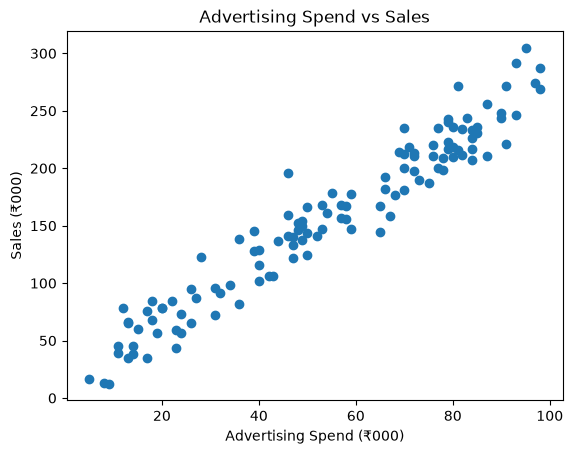

In [14]:
plt.scatter(X, y)
plt.xlabel("Advertising Spend (₹000)")
plt.ylabel("Sales (₹000)")
plt.title("Advertising Spend vs Sales")
plt.show()

In [15]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
from sklearn.model_selection import train_test_split

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(96, 1)
(24, 1)
(96,)
(24,)


In [18]:
from sklearn.linear_model import LinearRegression

In [19]:
model = LinearRegression()

In [20]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[2.61]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Advertising_Spend_Thousand_INR']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,15.57
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [21]:
print("Slope:", model.coef_)
print("Intercept:", model.intercept_)

Slope: [2.60649452]
Intercept: 15.570753059282055


In [22]:
y_pred = model.predict(X_test)

In [23]:
print(y_pred)

[ 44.24219279 250.15525995 135.46950102  39.02920375 127.65001746
 130.25651198  59.88115992 158.92795171  67.70064348 192.81238049
 237.12278734 119.8305339  271.00721611 242.33577638 234.51629282
 229.30330378 203.23835857  49.45518183 218.8773257  226.69680926
 109.40455581 271.00721611  83.3396106  226.69680926]


In [25]:
comparison = pd.DataFrame({
    'Actual_Sales': y_test.values,
    'Predicted_Sales': y_pred
})

comparison

,Actual_Sales,Predicted_Sales
0,39.47,44.242193
1,247.89,250.155260
2,140.86,135.469501
3,12.48,39.029204
4,105.88,127.650017
5,136.80,130.256512
6,34.67,59.881160
7,178.16,158.927952
8,78.00,67.700643
9,176.74,192.812380


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [27]:
mae = mean_absolute_error(y_test, y_pred)
print("MAE:", mae)

MAE: 14.600319806447745


In [30]:
mse = mean_squared_error(y_test, y_pred)
print("MSE:", mse)

MSE: 327.39336637556585


In [31]:
rmse = np.sqrt(mse)
print("RMSE:", rmse)

RMSE: 18.09401465611117


In [32]:
r2 = r2_score(y_test, y_pred)
print("R²:", r2)

R²: 0.9514672045803525


In [33]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 14.600319806447745
MSE: 327.39336637556585
RMSE: 18.09401465611117
R²: 0.9514672045803525


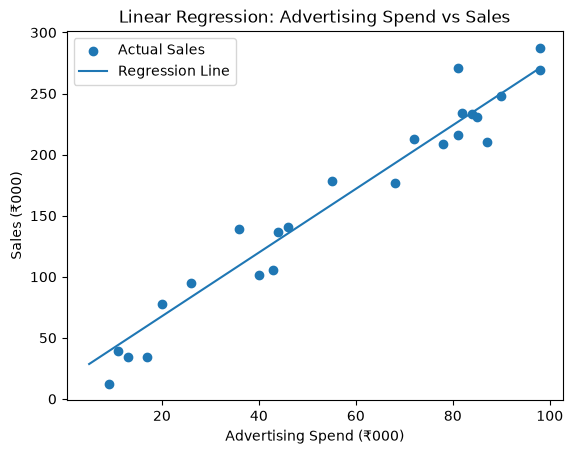

In [35]:
X_sorted = X.sort_values(by="Advertising_Spend_Thousand_INR")

plt.scatter(X_test, y_test, label="Actual Sales")
plt.plot(X_sorted, model.predict(X_sorted), label="Regression Line")

plt.xlabel("Advertising Spend (₹000)")
plt.ylabel("Sales (₹000)")
plt.title("Linear Regression: Advertising Spend vs Sales")
plt.legend()
plt.show()

In [36]:
m = 0
b = 0
learning_rate = 0.0001
iterations = 1000

In [37]:
x = X_train["Advertising_Spend_Thousand_INR"].values
y = y_train.values

n = len(x)

In [53]:
for i in range(iterations):

    y_pred_gd = m * x + b

    dm = (-2/n) * np.sum(x * (y - y_pred_gd))
    db = (-2/n) * np.sum(y - y_pred_gd)

    m = m - learning_rate * dm
    b = b - learning_rate * db

In [54]:
print("Gradient Descent slope:", m)
print("Gradient Descent intercept:", b)

print("Sklearn slope:", model.coef_[0])
print("Sklearn intercept:", model.intercept_)

Gradient Descent slope: 2.7714812243505538
Gradient Descent intercept: 4.743909842199998
Sklearn slope: 2.606494520973843
Sklearn intercept: 15.570753059282055


In [51]:
iterations = 10000

In [52]:
m = 0
b = 0

In [55]:
for i in range(iterations):

    y_pred_gd = m * x + b

    dm = (-2/n) * np.sum(x * (y - y_pred_gd))
    db = (-2/n) * np.sum(y - y_pred_gd)

    m = m - learning_rate * dm
    b = b - learning_rate * db

In [56]:
print("Gradient Descent slope:", m)
print("Gradient Descent intercept:", b)

print("Sklearn slope:", model.coef_[0])
print("Sklearn intercept:", model.intercept_)

Gradient Descent slope: 2.721535156935484
Gradient Descent intercept: 8.021496642501528
Sklearn slope: 2.606494520973843
Sklearn intercept: 15.570753059282055


In [57]:
m = 0
b = 0

learning_rate = 0.0001
iterations = 100000

In [58]:
for i in range(iterations):
    y_pred_gd = m * x + b

    dm = (-2/n) * np.sum(x * (y - y_pred_gd))
    db = (-2/n) * np.sum(y - y_pred_gd)

    m = m - learning_rate * dm
    b = b - learning_rate * db

In [59]:
print("Gradient Descent slope:", m)
print("Gradient Descent intercept:", b)

print("Sklearn slope:", model.coef_[0])
print("Sklearn intercept:", model.intercept_)

Gradient Descent slope: 2.6129224327237015
Gradient Descent intercept: 15.148937292892345
Sklearn slope: 2.606494520973843
Sklearn intercept: 15.570753059282055
